# Cảnh báo sớm khu vực sạc xe điện gần đầy bằng mạng LSTM

Notebook này thực hiện toàn bộ quy trình thử nghiệm chính: đọc dữ liệu UrbanEV, kiểm tra chất lượng, tính tỷ lệ lấp đầy, tạo nhãn cho giờ kế tiếp, xây dựng các mô hình đối chứng, huấn luyện LSTM và xuất kết quả cho báo cáo và web demo.

Bài toán được đặt như sau: tại thời điểm cuối một giờ, hệ thống nhìn lại 24 giờ gần nhất của một khu vực và dự đoán xác suất giờ kế tiếp có tỷ lệ trụ sạc đang bận từ 80% trở lên. Đây là bài toán phân loại nhị phân theo chuỗi thời gian.

## 1. Chuẩn bị thư viện và đường dẫn

Các thư viện dưới đây phục vụ cho ba việc chính. `pandas` đọc và biến đổi CSV, `scikit-learn` làm baseline và tính metric, còn `PyTorch` huấn luyện LSTM. Không tạo môi trường ảo trong notebook này.

In [1]:
from pathlib import Path
import json
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Khi chạy từ thư mục notebooks, thư mục cha là gốc project.
# Khi chạy từ gốc project, dùng luôn thư mục hiện tại.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'data' / 'UrbanEV'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts'
FIGURE_DIR = ARTIFACT_DIR / 'figures'
ARTIFACT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from ev_warning.data import FEATURE_COLUMNS, DEFAULT_THRESHOLD, load_panel_data, validate_panel_data
from ev_warning.metrics import evaluate_probabilities
from ev_warning.models import LSTMClassifier
from ev_warning.sequences import (
    flatten_last_state,
    fit_sequence_scaler,
    make_sequences,
    select_active_zones,
    split_by_time,
    transform_sequences,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Project root:', PROJECT_ROOT)
print('Data directory:', DATA_DIR)
print('Device:', DEVICE)

Project root: /Users/thanguit/Dev/ThacSiUIT/MonHoc/2026-2027/02_IS6109_HocSau_UngDungKinhDoanh/05_DoAn/02_CuoiKy/02_MaNguon/ev-charging-area-early-warning
Data directory: /Users/thanguit/Dev/ThacSiUIT/MonHoc/2026-2027/02_IS6109_HocSau_UngDungKinhDoanh/05_DoAn/02_CuoiKy/02_MaNguon/ev-charging-area-early-warning/data/UrbanEV
Device: mps


## 2. Đọc dữ liệu và kiểm tra chất lượng

Các file theo giờ có dạng rộng. Một dòng là một thời điểm, còn mỗi cột sau `time` là một khu vực. Hàm đọc dữ liệu chuyển bảng này thành dạng dài để mỗi dòng tương ứng với một cặp `khu vực - thời điểm`. Cách này giúp ghép nhiều file và tạo chuỗi cho từng khu vực rõ ràng hơn.

In [2]:
# Ngưỡng 0.80 nghĩa là ít nhất 80% số trụ trong khu vực đang bận.
THRESHOLD = DEFAULT_THRESHOLD
SEQUENCE_LENGTH = 24

panel = load_panel_data(DATA_DIR, threshold=THRESHOLD)
validation = validate_panel_data(panel)
print(json.dumps(validation, indent=2, ensure_ascii=False))

panel.head()

{
  "rows": 1194325,
  "zones": 275,
  "start": "2022-09-01 00:00:00",
  "end": "2023-02-28 22:00:00",
  "missing_values": 0,
  "missing_columns": [],
  "max_time_gap_hours": 1.0,
  "positive_rate": 0.012067904464865092,
  "occupancy_rate_min": 0.0,
  "occupancy_rate_max": 1.0
}


,time,zone_id,occupied_piles,duration_hours,volume_kwh,electricity_price,service_price,longitude,latitude,charge_count,...,perimeter,occupancy_rate,hour_sin,hour_cos,weekday_sin,weekday_cos,is_weekend,capacity_log,target_rate_next_hour,target_near_full
0,2022-09-01 00:00:00,1000,74.0,60.833333,330.458333,0.873429,0.739429,114.269504,22.720186,239,...,7337.7328,0.309623,0.000000,1.000000,0.433884,-0.900969,0.0,5.480639,0.242678,0
1,2022-09-01 01:00:00,1000,58.0,57.833333,311.208333,0.873429,0.739429,114.269504,22.720186,239,...,7337.7328,0.242678,0.258819,0.965926,0.433884,-0.900969,0.0,5.480639,0.292887,0
2,2022-09-01 02:00:00,1000,70.0,62.250000,332.208333,0.873429,0.739429,114.269504,22.720186,239,...,7337.7328,0.292887,0.500000,0.866025,0.433884,-0.900969,0.0,5.480639,0.288703,0
3,2022-09-01 03:00:00,1000,69.0,65.250000,345.041667,0.873429,0.739429,114.269504,22.720186,239,...,7337.7328,0.288703,0.707107,0.707107,0.433884,-0.900969,0.0,5.480639,0.259414,0
4,2022-09-01 04:00:00,1000,62.0,63.166667,336.583333,0.873429,0.739429,114.269504,22.720186,239,...,7337.7328,0.259414,0.866025,0.500000,0.433884,-0.900969,0.0,5.480639,0.259414,0


`occupancy.csv` trong bản dữ liệu hiện tại là số trụ đang bận. Vì mỗi khu vực có sức chứa khác nhau, không thể so sánh trực tiếp con số 80 trụ giữa hai khu vực. Ta dùng `zone-information.csv` để tính `occupancy_rate = occupied_piles / charge_count`. Nhãn `target_near_full` lấy tỷ lệ của giờ kế tiếp, không lấy tỷ lệ hiện tại.

In [3]:
# Tóm tắt các biến quan trọng để nhìn nhanh thang đo của dữ liệu.
summary = panel[[
    'occupied_piles', 'charge_count', 'occupancy_rate',
    'duration_hours', 'volume_kwh', 'electricity_price', 'service_price',
    'target_near_full'
]] .describe().T
summary

,count,mean,std,min,25%,50%,75%,max
occupied_piles,1194325.0,17.865717,21.013613,0.00000,5.000000,11.000000,23.000000,373.000000
charge_count,1194325.0,85.240000,77.952936,4.00000,28.000000,58.000000,115.000000,446.000000
occupancy_rate,1194325.0,0.226701,0.167418,0.00000,0.111111,0.192825,0.296296,1.000000
duration_hours,1194325.0,13.105098,17.219127,0.00000,2.666667,7.000000,16.250000,207.583333
volume_kwh,1194325.0,261.468391,859.796753,0.00000,18.666667,53.666667,152.583333,16732.500000
electricity_price,1194325.0,0.951200,0.194884,0.23806,0.816667,0.960000,1.060000,1.800000
service_price,1194325.0,0.724063,0.128990,0.00000,0.710000,0.760000,0.760000,1.450000
target_near_full,1194325.0,0.012068,0.109189,0.00000,0.000000,0.000000,0.000000,1.000000


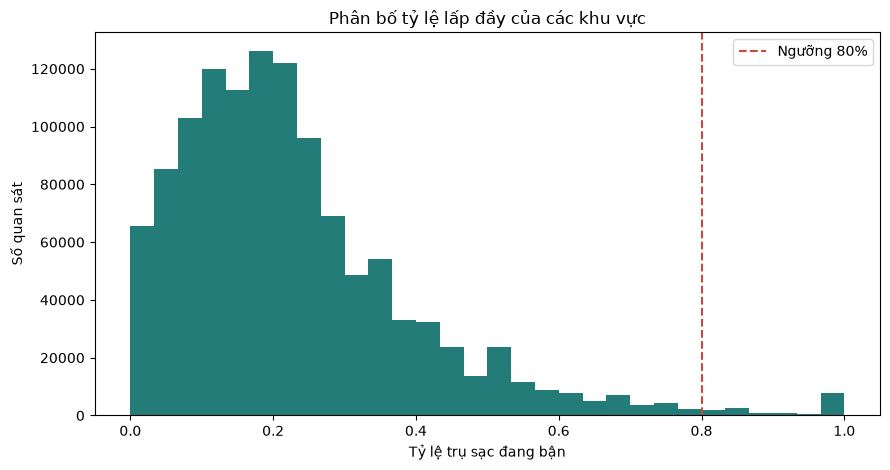

In [4]:
# Biểu đồ 1: phân bố tỷ lệ lấp đầy.
plt.figure(figsize=(9, 4.8))
plt.hist(panel['occupancy_rate'], bins=30, color='#0b6e69', alpha=0.9)
plt.axvline(THRESHOLD, color='#c64b3c', linestyle='--', label=f'Ngưỡng {THRESHOLD:.0%}')
plt.xlabel('Tỷ lệ trụ sạc đang bận')
plt.ylabel('Số quan sát')
plt.title('Phân bố tỷ lệ lấp đầy của các khu vực')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_occupancy_distribution.png', dpi=180)
plt.show()

## 3. Chọn khu vực và tạo chuỗi 24 giờ

Dữ liệu có 275 khu vực. Một số khu vực gần như không bao giờ đạt ngưỡng 80%, nếu đưa vào thì mô hình có rất ít ví dụ dương để học. Notebook chọn tối đa 35 khu vực có ít nhất 10 sự kiện gần đầy. Mỗi cửa sổ được lấy cách nhau 3 giờ để giảm bản sao dữ liệu trong bộ nhớ, còn mỗi cửa sổ vẫn nhìn lại đủ 24 giờ. Đây là bước giới hạn phạm vi thử nghiệm để chạy ổn định trên laptop, không phải xóa dữ liệu gốc.

In [5]:
# Chọn các khu vực có đủ số lần chạm ngưỡng để hai lớp có ý nghĩa.
selected_zones = select_active_zones(
    panel,
    threshold=THRESHOLD,
    max_zones=35,
    min_positive_events=10,
)
print('Số khu vực được dùng:', len(selected_zones))
print('Các khu vực đầu tiên:', selected_zones[:10])

X, y, meta = make_sequences(
    panel,
    feature_columns=FEATURE_COLUMNS,
    sequence_length=SEQUENCE_LENGTH,
    zones=selected_zones,
    stride=3,
)
print('Kích thước X:', X.shape)
print('Kích thước y:', y.shape)
print('Tỷ lệ lớp dương:', y.mean())

Số khu vực được dùng: 35
Các khu vực đầu tiên: ['1029', '890', '651', '568', '570', '719', '575', '559', '771', '881']
Kích thước X: (50400, 24, 11)
Kích thước y: (50400,)
Tỷ lệ lớp dương: 0.09279761904761905


Một mẫu trong `X` có dạng `24 x 11`. 24 là 24 giờ gần nhất, 11 là số đặc trưng tại mỗi giờ. LSTM đọc từng hàng theo thứ tự thời gian. `y` là nhãn của giờ thứ 25, tức giờ ngay sau cửa sổ quan sát.

In [6]:
splits = split_by_time(
    X, y, meta,
    train_end='2023-01-01',
    validation_end='2023-02-01',
)

for split_name, split in splits.items():
    print(
        split_name,
        'samples=', len(split.y),
        'positive_rate=', round(float(split.y.mean()), 4),
        'from=', split.meta['target_time'].min(),
        'to=', split.meta['target_time'].max(),
    )

train samples= 33880 positive_rate= 0.0911 from= 2022-09-02 00:00:00 to= 2022-12-31 21:00:00
validation samples= 8680 positive_rate= 0.103 from= 2023-01-01 00:00:00 to= 2023-01-31 21:00:00
test samples= 7840 positive_rate= 0.089 from= 2023-02-01 00:00:00 to= 2023-02-28 21:00:00


Chia theo thời gian quan trọng hơn chia ngẫu nhiên. Nếu trộn ngẫu nhiên, các cửa sổ rất gần nhau hoặc cùng một giai đoạn có thể lọt vào cả train và test. Khi đó kết quả đẹp hơn thực tế. Scaler cũng chỉ được fit trên train.

In [7]:
# Fit chuẩn hóa trên train, sau đó áp dụng cùng phép biến đổi cho validation và test.
scaler = fit_sequence_scaler(splits['train'].x)
for split in splits.values():
    split.x = transform_sequences(split.x, scaler)

# Hạn chế số dòng huấn luyện cho mỗi baseline để notebook chạy nhanh trên laptop.
MAX_TRAIN_ROWS = 20000
def limit_training_rows(split, max_rows=MAX_TRAIN_ROWS):
    if len(split.y) <= max_rows:
        return split.x, split.y
    rng = np.random.default_rng(SEED)
    indices = rng.choice(len(split.y), size=max_rows, replace=False)
    return split.x[indices], split.y[indices]

train_x, train_y = limit_training_rows(splits['train'])
print('Số mẫu dùng huấn luyện:', len(train_y))
print('Tỷ lệ lớp dương sau giới hạn:', train_y.mean())

Số mẫu dùng huấn luyện: 20000
Tỷ lệ lớp dương sau giới hạn: 0.0898


## 4. Baseline trên dữ liệu dạng bảng

Baseline là mốc so sánh. Ta trải phẳng 24 giờ thành một vector dài rồi đưa vào Logistic Regression và Histogram Gradient Boosting. Nếu LSTM không tốt hơn baseline, ta phải thừa nhận rằng chuỗi chưa đem lại lợi ích đủ lớn hoặc dữ liệu dạng bảng đã chứa phần lớn tín hiệu.

In [8]:
X_train_table = flatten_last_state(train_x)
X_validation_table = flatten_last_state(splits['validation'].x)
X_test_table = flatten_last_state(splits['test'].x)

# class_weight='balanced' giúp baseline chú ý hơn đến lớp gần đầy vốn ít hơn.
logistic = LogisticRegression(
    max_iter=200,
    class_weight='balanced',
    solver='liblinear',
    random_state=SEED,
)
logistic.fit(X_train_table, train_y)

# Histogram Gradient Boosting cũng xây nhiều cây tuần tự để sửa sai cho các cây trước.
# Dùng bản có sẵn trong scikit-learn giúp notebook ổn định trên Python Homebrew.
tree_model = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=31,
    learning_rate=0.05,
    l2_regularization=1.0,
    random_state=SEED,
)
sample_weights = compute_sample_weight(class_weight='balanced', y=train_y)
tree_model.fit(X_train_table, train_y, sample_weight=sample_weights)

baseline_probabilities = {
    'Logistic Regression': logistic.predict_proba(X_test_table)[:, 1],
    'Histogram Gradient Boosting': tree_model.predict_proba(X_test_table)[:, 1],
}
baseline_metrics = {
    name: evaluate_probabilities(splits['test'].y, probabilities)
    for name, probabilities in baseline_probabilities.items()
}
pd.DataFrame(baseline_metrics).T

,log_loss,brier_score,pr_auc,precision,recall,f1,roc_auc
Logistic Regression,0.277811,0.084597,0.913949,0.426683,0.971347,0.592916,0.984949
Histogram Gradient Boosting,0.152730,0.040803,0.959897,0.618299,0.958453,0.751685,0.989884


## 5. Huấn luyện LSTM

LSTM nhận tensor có dạng `batch x 24 x 11`. Ở mỗi giờ, mạng cập nhật trạng thái ẩn để giữ lại thông tin cần thiết từ lịch sử. Lớp cuối biến trạng thái của giờ cuối thành một logit, sau đó sigmoid biến logit thành xác suất gần đầy.

In [9]:
def make_loader(x, y, batch_size=512, shuffle=False):
    # TensorDataset ghép mỗi chuỗi với đúng một nhãn giờ kế tiếp.
    dataset = TensorDataset(
        torch.from_numpy(x),
        torch.from_numpy(y.astype(np.float32)),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(train_x, train_y, shuffle=True)
validation_loader = make_loader(splits['validation'].x, splits['validation'].y)
test_loader = make_loader(splits['test'].x, splits['test'].y)

model = LSTMClassifier(input_size=len(FEATURE_COLUMNS), hidden_size=64).to(DEVICE)
positive = max(float(train_y.sum()), 1.0)
negative = max(float(len(train_y) - train_y.sum()), 1.0)
positive_weight = torch.tensor([negative / positive], dtype=torch.float32, device=DEVICE)
loss_function = nn.BCEWithLogitsLoss(pos_weight=positive_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(loader, training):
    model.train(training)
    losses = []
    for batch_x, batch_y in loader:
        batch_x = batch_x.to(DEVICE)
        batch_y = batch_y.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits = model(batch_x)
            loss = loss_function(logits, batch_y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

history = []
best_state = None
best_validation_loss = float('inf')
patience = 3
stale_epochs = 0

for epoch in range(1, 9):
    train_loss = run_epoch(train_loader, training=True)
    validation_loss = run_epoch(validation_loader, training=False)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'validation_loss': validation_loss})
    print(f'Epoch {epoch:02d}: train={train_loss:.4f}, validation={validation_loss:.4f}')
    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= patience:
            break

if best_state is not None:
    model.load_state_dict(best_state)

history_frame = pd.DataFrame(history)
history_frame

Epoch 01: train=0.7858, validation=0.5094


Epoch 02: train=0.6796, validation=0.4897


Epoch 03: train=0.6336, validation=0.4358


Epoch 04: train=0.6118, validation=0.4306


Epoch 05: train=0.5934, validation=0.3991


Epoch 06: train=0.5719, validation=0.4013


Epoch 07: train=0.5549, validation=0.3787


Epoch 08: train=0.5609, validation=0.3534


,epoch,train_loss,validation_loss
0,1,0.785796,0.509387
1,2,0.679647,0.489740
2,3,0.633617,0.435843
3,4,0.611791,0.430551
4,5,0.593365,0.399105
5,6,0.571935,0.401252
6,7,0.554950,0.378682
7,8,0.560886,0.353421


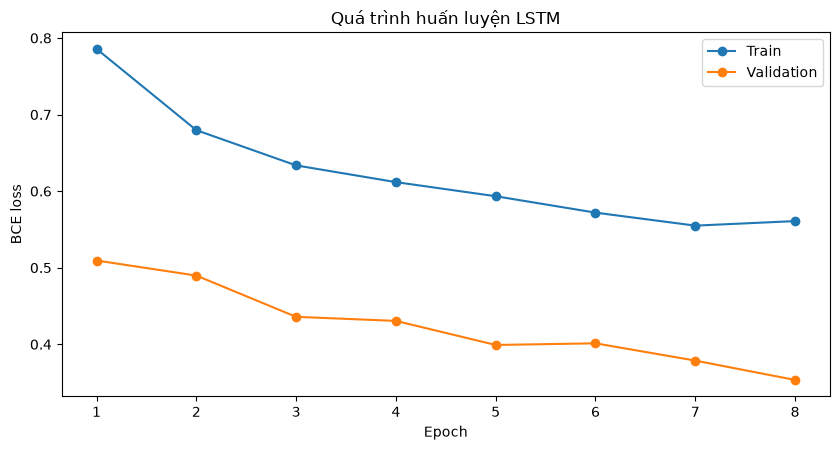

In [10]:
# Biểu đồ 2: loss train và validation để kiểm tra dấu hiệu overfitting.
plt.figure(figsize=(8.5, 4.6))
plt.plot(history_frame['epoch'], history_frame['train_loss'], marker='o', label='Train')
plt.plot(history_frame['epoch'], history_frame['validation_loss'], marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('BCE loss')
plt.title('Quá trình huấn luyện LSTM')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_lstm_training_curve.png', dpi=180)
plt.show()

In [11]:
def predict_lstm(loader):
    # Tắt gradient vì giai đoạn này chỉ cần suy luận, không cập nhật trọng số.
    model.eval()
    probabilities = []
    with torch.no_grad():
        for batch_x, _ in loader:
            logits = model(batch_x.to(DEVICE))
            probabilities.extend(torch.sigmoid(logits).cpu().numpy())
    return np.asarray(probabilities)

lstm_probabilities = predict_lstm(test_loader)
metrics = dict(baseline_metrics)
metrics['LSTM'] = evaluate_probabilities(splits['test'].y, lstm_probabilities)
metrics_frame = pd.DataFrame(metrics).T.sort_values('pr_auc', ascending=False)
metrics_frame

,log_loss,brier_score,pr_auc,precision,recall,f1,roc_auc
Histogram Gradient Boosting,0.152730,0.040803,0.959897,0.618299,0.958453,0.751685,0.989884
LSTM,0.190602,0.056665,0.949695,0.532800,0.954155,0.683778,0.988185
Logistic Regression,0.277811,0.084597,0.913949,0.426683,0.971347,0.592916,0.984949


Trong bài toán cảnh báo, Recall quan trọng vì bỏ sót một khu vực sắp đầy có thể làm người dùng không tìm được chỗ sạc. Tuy nhiên, chỉ tăng Recall bằng cách cảnh báo tất cả khu vực cũng không tốt. Vì vậy báo cáo đọc đồng thời PR-AUC, Precision, Recall, F1, Log Loss và Brier Score.

In [12]:
# Lưu metric và dự đoán để web demo dùng lại mà không phải huấn luyện khi mở trang.
metrics_frame.to_csv(ARTIFACT_DIR / 'metrics.csv')

prediction_frame = splits['test'].meta.copy()
prediction_frame['actual'] = splits['test'].y
prediction_frame['lstm_probability'] = lstm_probabilities
prediction_frame['lstm_prediction'] = (lstm_probabilities >= 0.5).astype(int)
prediction_frame.to_csv(ARTIFACT_DIR / 'test_predictions.csv', index=False)

with open(ARTIFACT_DIR / 'run_summary.json', 'w', encoding='utf-8') as file:
    json.dump({
        'threshold': THRESHOLD,
        'sequence_length_hours': SEQUENCE_LENGTH,
        'selected_zones': selected_zones,
        'feature_columns': FEATURE_COLUMNS,
        'device': str(DEVICE),
        'metrics': metrics,
    }, file, ensure_ascii=False, indent=2)

print('Đã ghi kết quả vào:', ARTIFACT_DIR)

Đã ghi kết quả vào: /Users/thanguit/Dev/ThacSiUIT/MonHoc/2026-2027/02_IS6109_HocSau_UngDungKinhDoanh/05_DoAn/02_CuoiKy/02_MaNguon/ev-charging-area-early-warning/artifacts


## 8. Sinh các hình dùng trong báo cáo

Các hình dưới đây được tạo từ đúng các biến đã dùng để đánh giá mô hình. Việc lưu riêng từng hình giúp báo cáo có thể dẫn lại kết quả mà không cần chụp màn hình từ notebook.

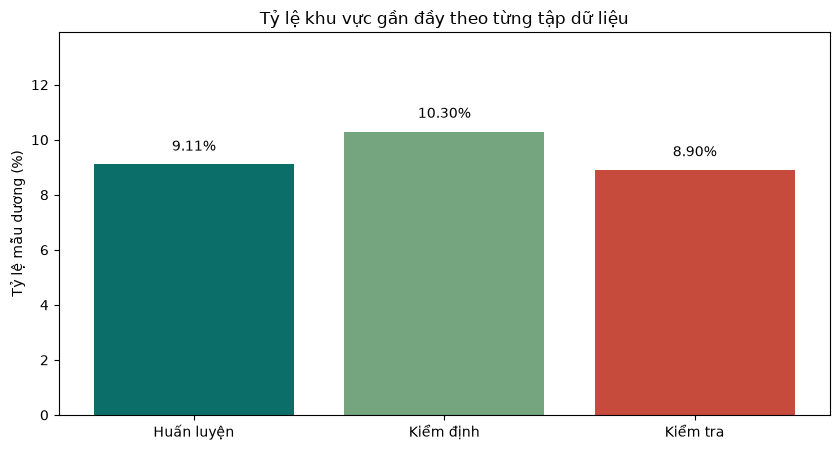

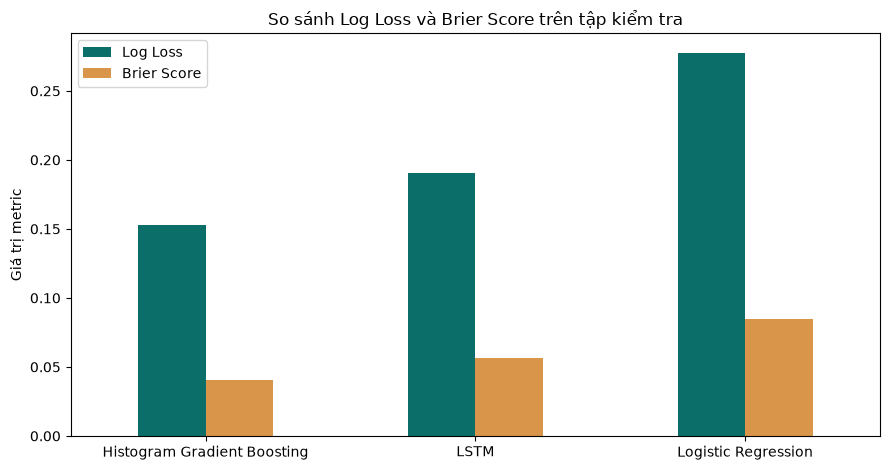

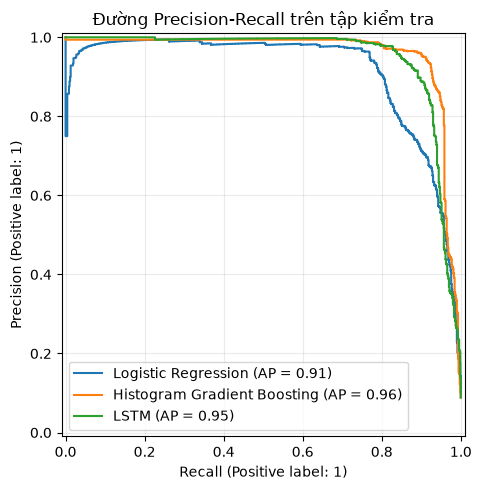

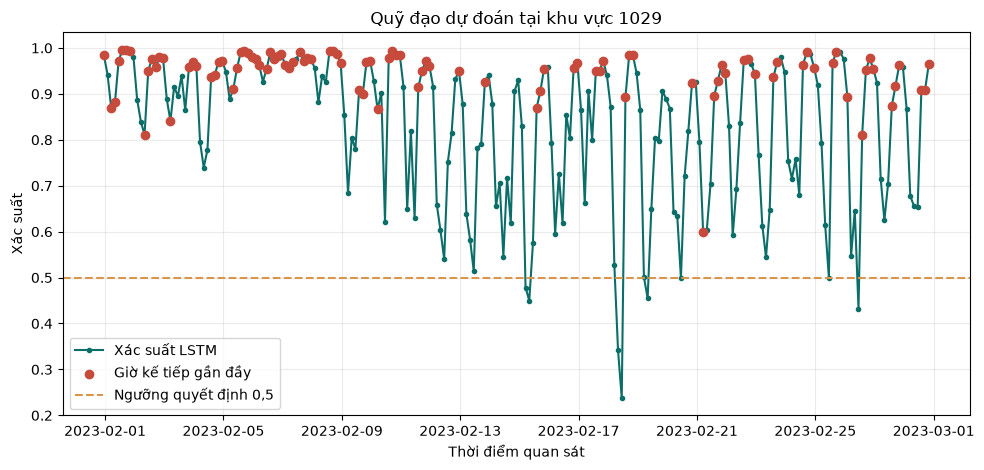

Đã lưu thêm các hình đánh giá và xác suất baseline vào: /Users/thanguit/Dev/ThacSiUIT/MonHoc/2026-2027/02_IS6109_HocSau_UngDungKinhDoanh/05_DoAn/02_CuoiKy/02_MaNguon/ev-charging-area-early-warning/artifacts/figures


In [13]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

# Hình 3: tỷ lệ mẫu dương trong ba tập theo đúng cách chia theo thời gian.
split_summary = pd.DataFrame({
    'Tập': ['Huấn luyện', 'Kiểm định', 'Kiểm tra'],
    'Tỷ lệ gần đầy': [splits['train'].y.mean(), splits['validation'].y.mean(), splits['test'].y.mean()],
})
fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.bar(split_summary['Tập'], split_summary['Tỷ lệ gần đầy'] * 100, color=['#0b6e69', '#74a57f', '#c64b3c'])
ax.set_ylabel('Tỷ lệ mẫu dương (%)')
ax.set_title('Tỷ lệ khu vực gần đầy theo từng tập dữ liệu')
ax.set_ylim(0, max(split_summary['Tỷ lệ gần đầy'] * 100) * 1.35)
for bar, value in zip(bars, split_summary['Tỷ lệ gần đầy'] * 100):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f'{value:.2f}%', ha='center')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '03_class_distribution.png', dpi=180)
plt.show()

# Hình 4: so sánh hai metric đánh giá xác suất. Giá trị thấp hơn là tốt hơn.
plot_metrics = metrics_frame[['log_loss', 'brier_score']].copy()
ax = plot_metrics.plot(kind='bar', figsize=(9, 4.8), color=['#0b6e69', '#d9964a'])
ax.set_xlabel('')
ax.set_ylabel('Giá trị metric')
ax.set_title('So sánh Log Loss và Brier Score trên tập kiểm tra')
ax.legend(['Log Loss', 'Brier Score'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_probability_metrics.png', dpi=180)
plt.show()

# Hình 5: đường Precision-Recall của các mô hình.
fig, ax = plt.subplots(figsize=(8.5, 5))
for model_name, probabilities in {**baseline_probabilities, 'LSTM': lstm_probabilities}.items():
    PrecisionRecallDisplay.from_predictions(splits['test'].y, probabilities, name=model_name, ax=ax)
ax.set_title('Đường Precision-Recall trên tập kiểm tra')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '05_precision_recall.png', dpi=180)
plt.show()

# Hình 6: một ví dụ về xác suất dự đoán theo thời gian tại một khu vực.
example_zone = selected_zones[0]
example = prediction_frame[prediction_frame['zone_id'] == example_zone].copy()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(pd.to_datetime(example['observation_time']), example['lstm_probability'], color='#0b6e69', marker='o', markersize=3, label='Xác suất LSTM')
ax.scatter(pd.to_datetime(example.loc[example['actual'] == 1, 'observation_time']), example.loc[example['actual'] == 1, 'lstm_probability'], color='#c64b3c', zorder=3, label='Giờ kế tiếp gần đầy')
ax.axhline(0.5, color='#d9964a', linestyle='--', label='Ngưỡng quyết định 0,5')
ax.set_xlabel('Thời điểm quan sát')
ax.set_ylabel('Xác suất')
ax.set_title(f'Quỹ đạo dự đoán tại khu vực {example_zone}')
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '06_probability_trajectory.png', dpi=180)
plt.show()

# Lưu thêm xác suất của hai baseline để báo cáo có thể tái kiểm tra.
prediction_frame['logistic_probability'] = baseline_probabilities['Logistic Regression']
prediction_frame['hist_gradient_boosting_probability'] = baseline_probabilities['Histogram Gradient Boosting']
prediction_frame.to_csv(ARTIFACT_DIR / 'test_predictions.csv', index=False)
print('Đã lưu thêm các hình đánh giá và xác suất baseline vào:', FIGURE_DIR)